In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import seaborn as sns
import os
from PIL import Image 
import cv2

In [2]:

DATASET_DIR = Path("../dataset/complete_set")

DATASET_REAL_DIR = DATASET_DIR / 'real'
DATASET_FAKE_DIR = DATASET_DIR / 'fake'

real_files = os.listdir(DATASET_REAL_DIR)
fake_files = os.listdir(DATASET_FAKE_DIR)

## Distribution of image sizes

c:\Users\leiya\anaconda3\envs\car_racing_env\lib\site-packages\PIL\Image.py:3368: DecompressionBombWarning: Image size (143040000 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
c:\Users\leiya\anaconda3\envs\car_racing_env\lib\site-packages\PIL\Image.py:3368: DecompressionBombWarning: Image size (121554000 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


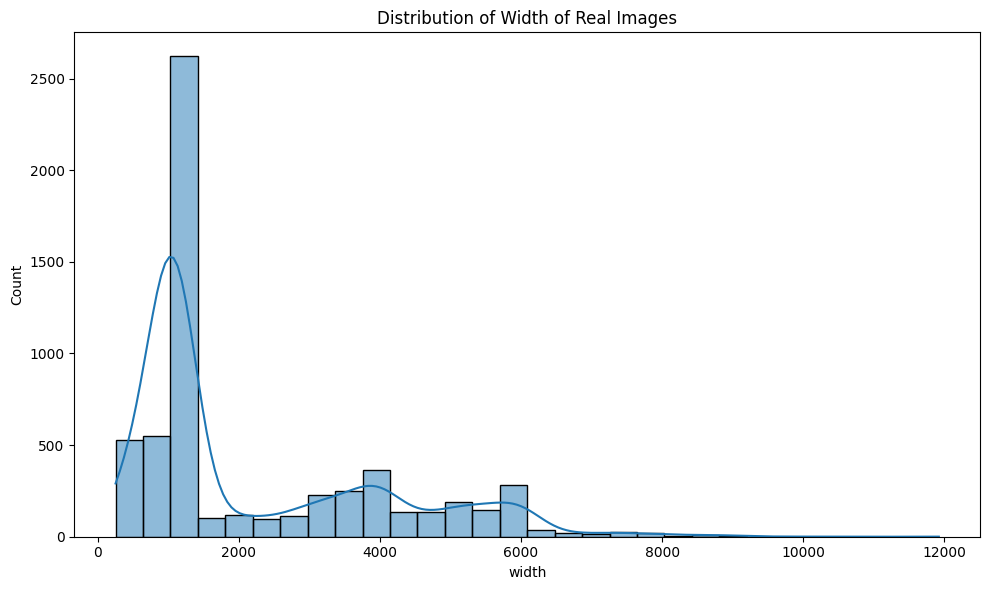

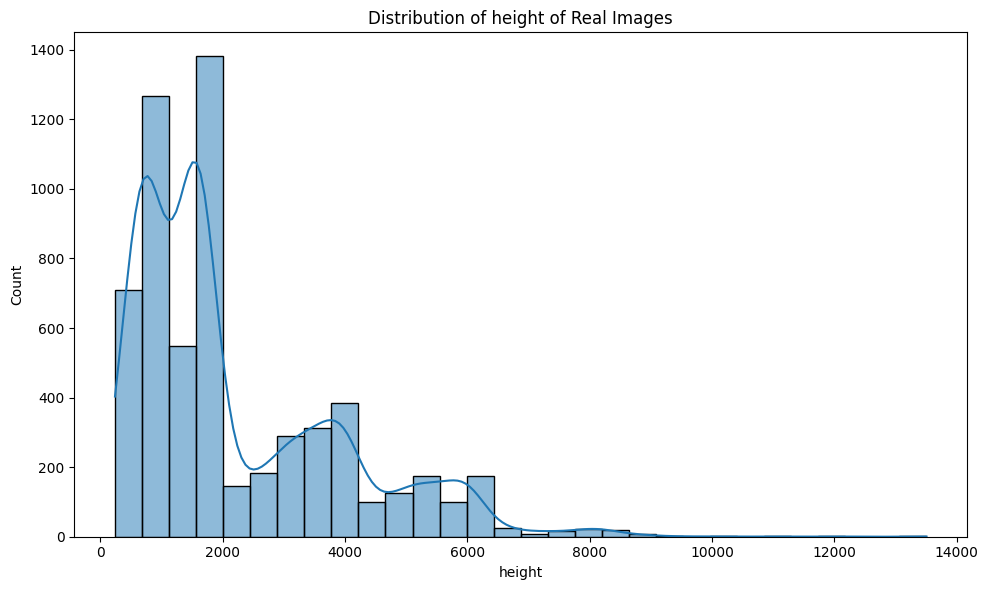

In [3]:
real_size = []
if os.path.exists("../EDA/figures") == False:
    os.makedirs("../EDA/figures")
figure_folder = Path("../EDA/figures")

for file in real_files:
    img = Image.open(f"{DATASET_REAL_DIR}/{file}")
    real_size.append((file,img.size[0], img.size[1]))

real_images_df = pd.DataFrame(real_size, columns=['name','width', 'height'])
real_images_df.describe()

plt.figure(figsize=(10, 6))
sns.histplot(real_images_df['width'], bins=30, kde=True)
plt.title('Distribution of Width of Real Images')
plt.tight_layout()
plt.savefig(figure_folder / 'real_images_width_distribution.png')
plt.show()



plt.figure(figsize=(10, 6))
sns.histplot(real_images_df['height'], bins=30, kde=True)
plt.title('Distribution of height of Real Images')
plt.tight_layout()
plt.savefig(figure_folder / 'real_images_height_distribution.png')
plt.show()

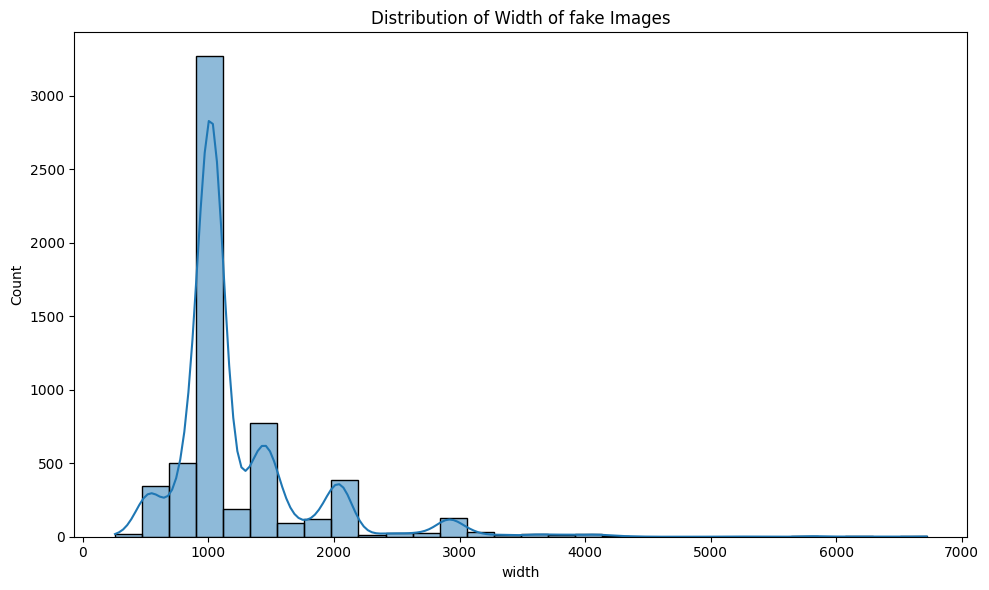

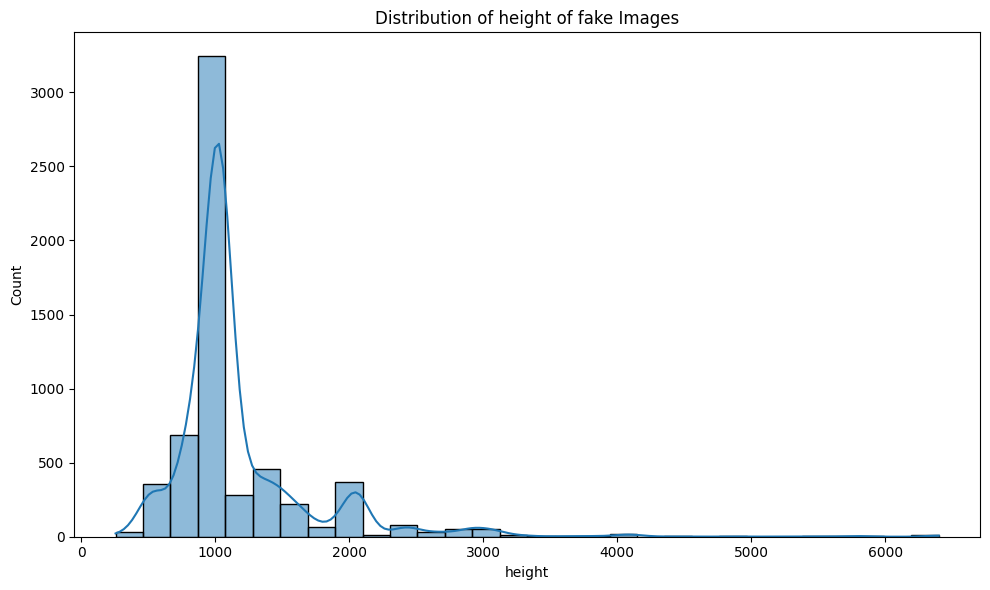

In [4]:
fake_size = []

for file in fake_files:
    img = Image.open(f"{DATASET_FAKE_DIR}/{file}")
    fake_size.append((file,img.size[0], img.size[1]))

fake_images_df = pd.DataFrame(fake_size, columns=['name','width', 'height'])
fake_images_df.describe()

plt.figure(figsize=(10, 6))
sns.histplot(fake_images_df['width'], bins=30, kde=True)
plt.title('Distribution of Width of fake Images')
plt.tight_layout()
plt.savefig(figure_folder / 'fake_images_width_distribution.png')
plt.show()

plt.figure(figsize=(10, 6))
sns.histplot(fake_images_df['height'], bins=30, kde=True)
plt.title('Distribution of height of fake Images')
plt.tight_layout()
plt.savefig(figure_folder / 'fake_images_height_distribution.png')
plt.show()

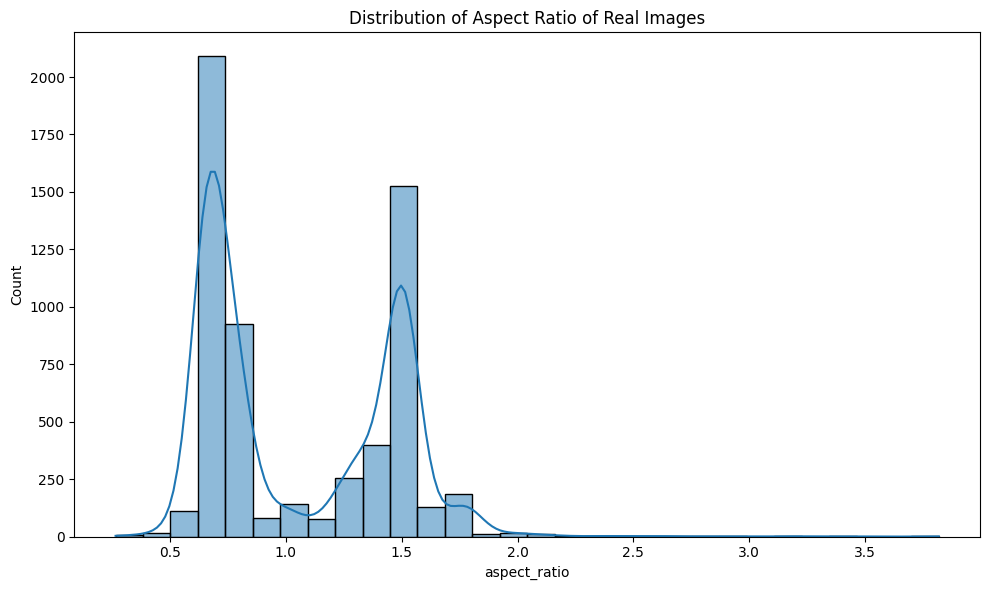

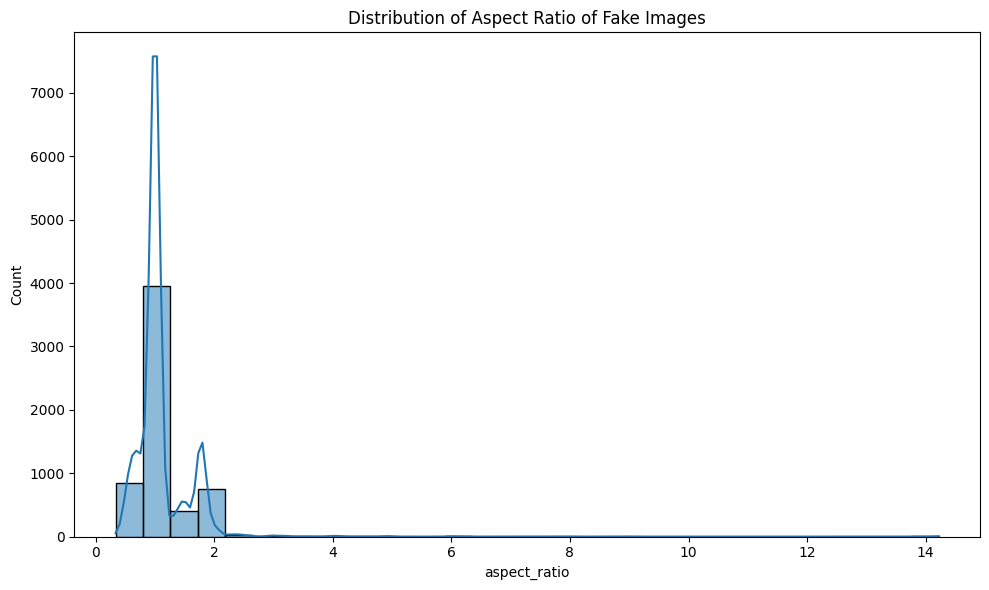

In [5]:
real_images_df['aspect_ratio'] = real_images_df['width'] / real_images_df['height']
fake_images_df['aspect_ratio'] = fake_images_df['width'] / fake_images_df['height']

plt.figure(figsize=(10, 6))
sns.histplot(real_images_df['aspect_ratio'], bins=30, kde=True)
plt.title('Distribution of Aspect Ratio of Real Images')
plt.tight_layout()
plt.savefig(figure_folder / 'real_images_aspect_ratio_distribution.png')
plt.show()

plt.figure(figsize=(10, 6))
sns.histplot(fake_images_df['aspect_ratio'], bins=30, kde=True)
plt.title('Distribution of Aspect Ratio of Fake Images')
plt.tight_layout()
plt.savefig(figure_folder / 'fake_images_aspect_ratio_distribution.png')
plt.show()

# Distribution of colors

## Real images

In [6]:
real_colors = []

for file in real_files:
    img = cv2.imread(f"{DATASET_REAL_DIR}/{file}")
    
    if img is None:
        print(f"Skipping corrupted or non-existent image: {file}")
        continue  # Skip this iteration
    
    avg_color = np.mean(img, axis=(0, 1))
    real_colors.append(avg_color)

real_colors_df = pd.DataFrame(real_colors, columns=['red', 'green', 'blue'])

Skipping corrupted or non-existent image: 5879.jpg


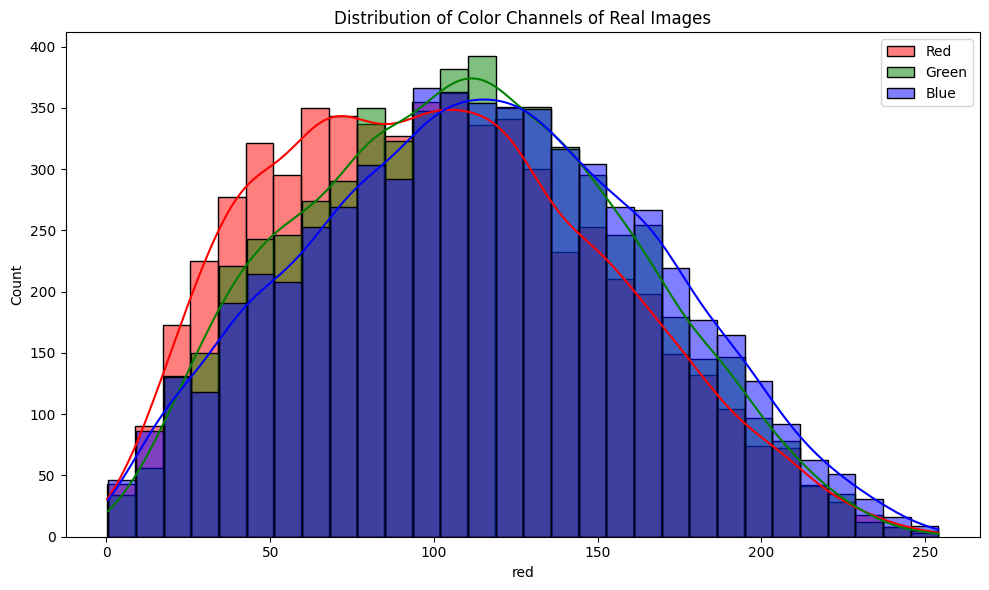

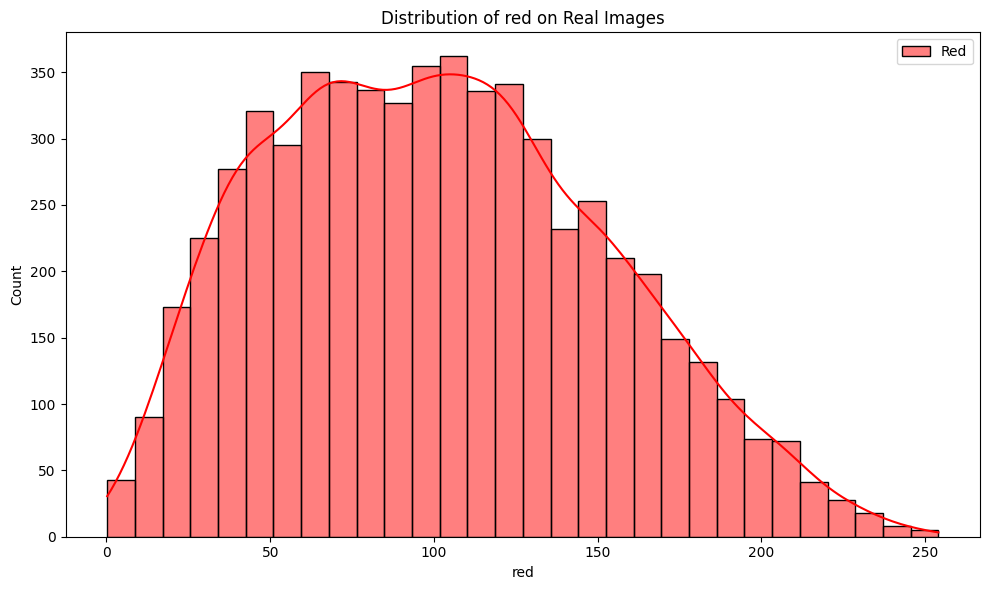

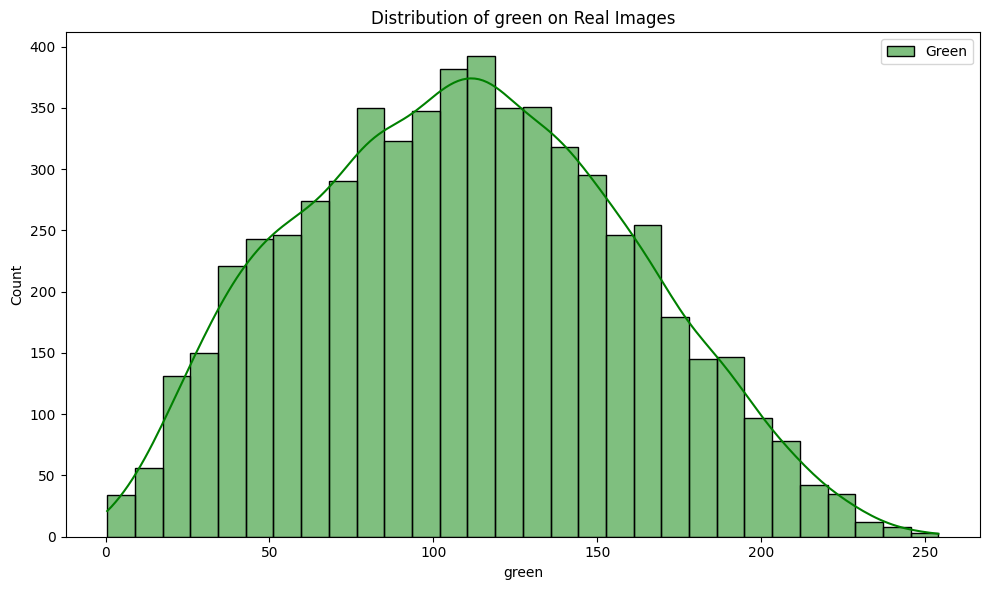

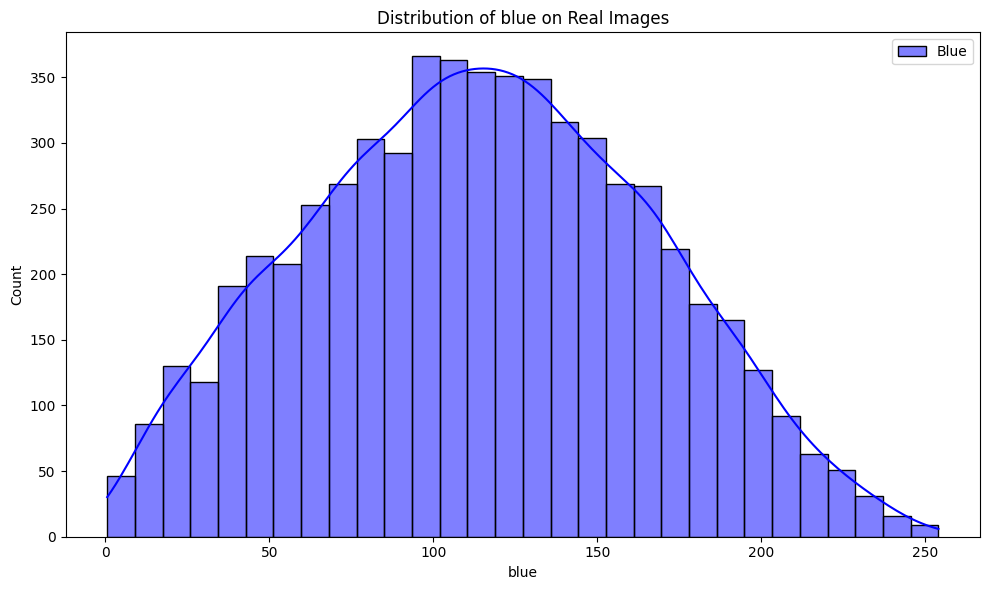

In [7]:

plt.figure(figsize=(10, 6))
sns.histplot(real_colors_df['red'], bins=30, kde=True, color='red', label='Red')
sns.histplot(real_colors_df['green'], bins=30, kde=True, color='green', label='Green')
sns.histplot(real_colors_df['blue'], bins=30, kde=True, color='blue', label='Blue')
plt.title('Distribution of Color Channels of Real Images')
plt.legend()
plt.tight_layout()
plt.savefig(figure_folder / 'real_images_color_distribution.png')
plt.show()

plt.figure(figsize=(10, 6))
sns.histplot(real_colors_df['red'], bins=30, kde=True, color='red', label='Red')
plt.title('Distribution of red on Real Images')
plt.legend()
plt.tight_layout()
plt.savefig(figure_folder / 'real_images_red_distribution.png')
plt.show()

plt.figure(figsize=(10, 6))
sns.histplot(real_colors_df['green'], bins=30, kde=True, color='green', label='Green')
plt.title('Distribution of green on Real Images')
plt.legend()
plt.tight_layout()
plt.savefig(figure_folder / 'real_images_green_distribution.png')
plt.show()

plt.figure(figsize=(10, 6))
sns.histplot(real_colors_df['blue'], bins=30, kde=True, color='blue', label='Blue')
plt.title('Distribution of blue on Real Images')
plt.legend()
plt.tight_layout()
plt.savefig(figure_folder / 'real_images_blue_distribution.png')
plt.show()

## Fakes images

In [8]:
fake_colors = []

for file in fake_files:
    img = cv2.imread(f"{DATASET_FAKE_DIR}/{file}")
    
    if img is None:
        print(f"Skipping corrupted or non-existent image: {file}")
        continue  # Skip this iteration
    
    avg_color = np.mean(img, axis=(0, 1))
    fake_colors.append(avg_color)

fake_colors_df = pd.DataFrame(fake_colors, columns=['red', 'green', 'blue'])

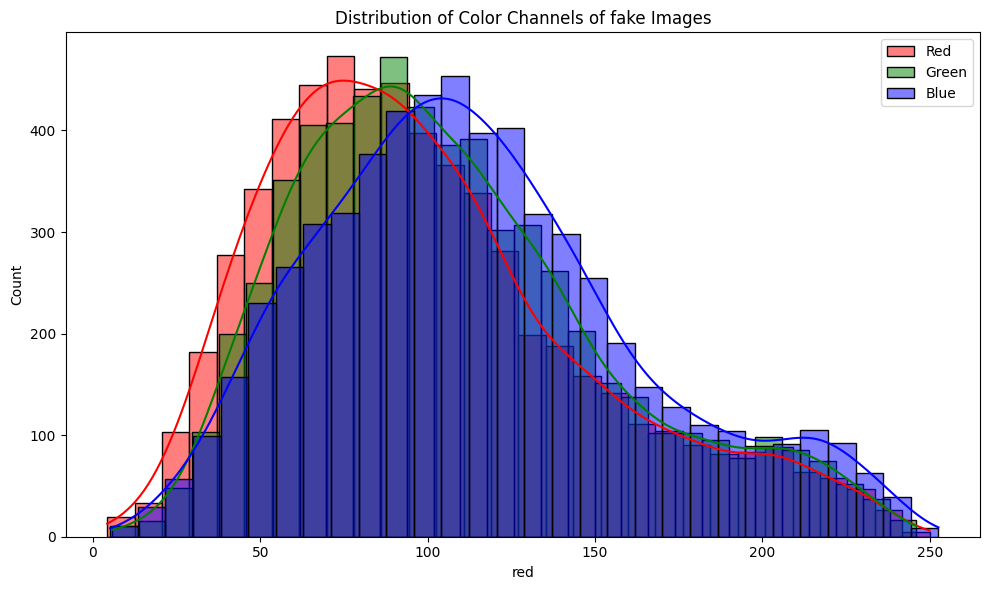

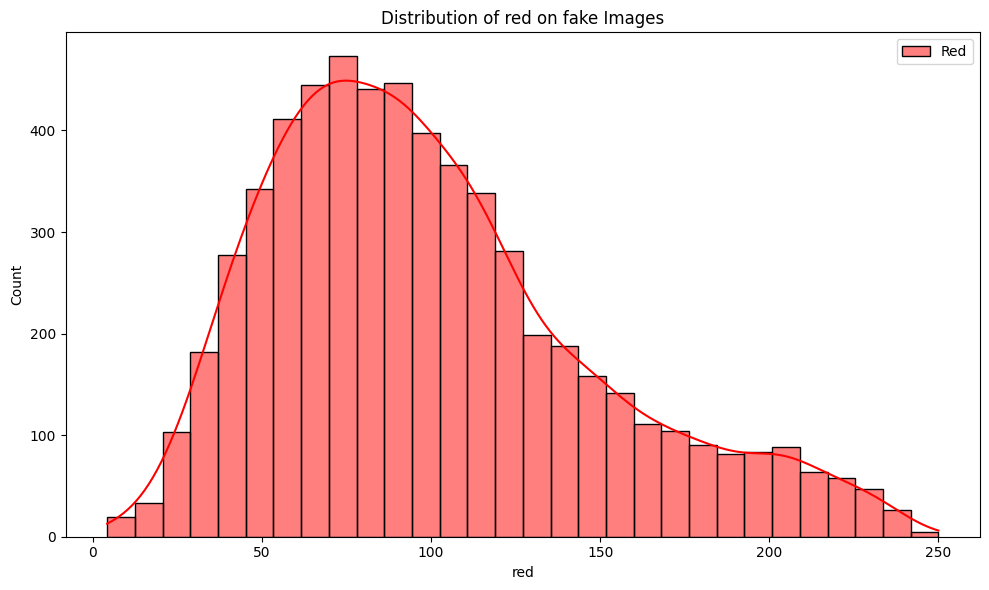

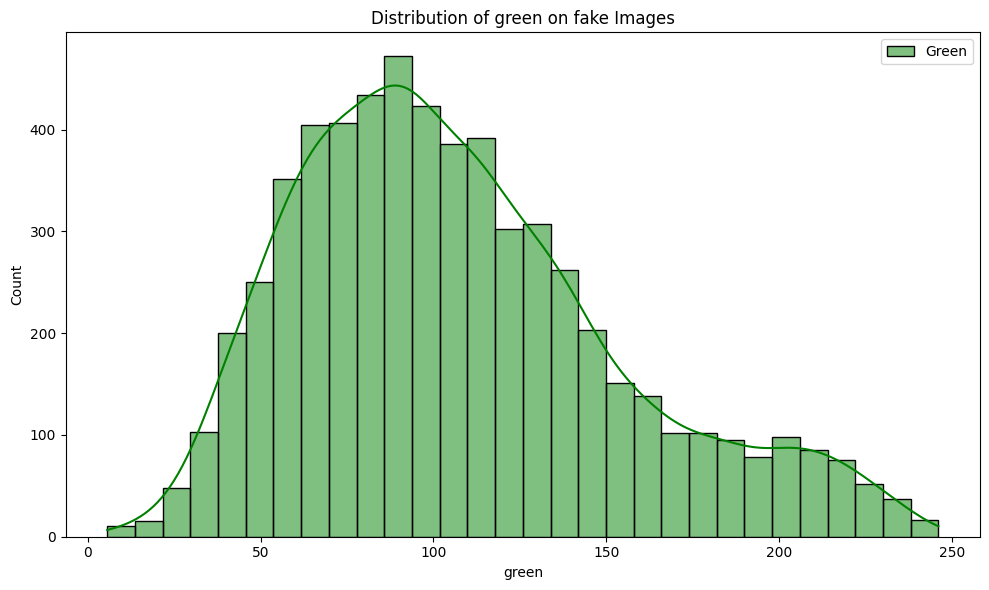

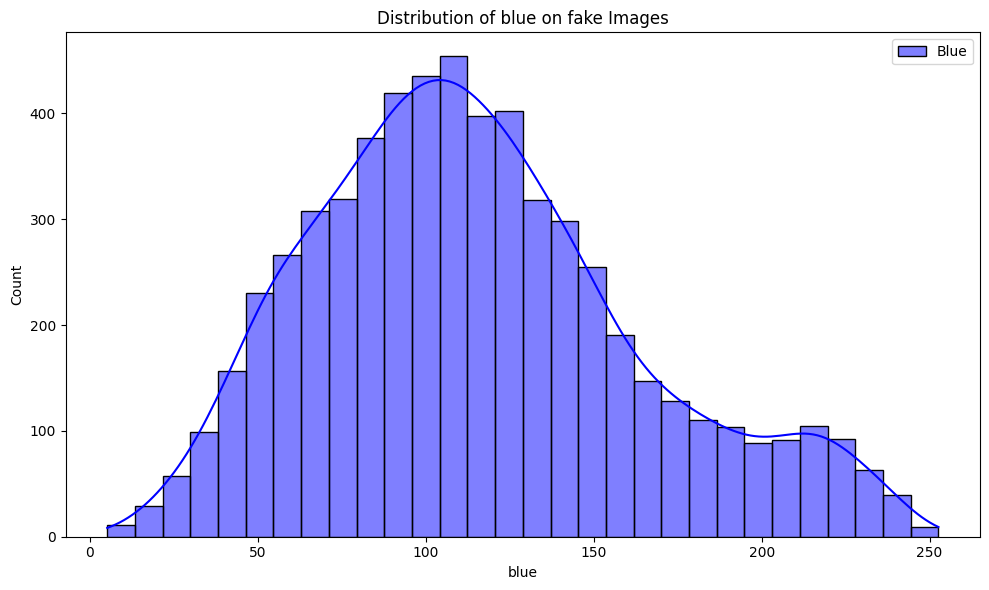

In [9]:
plt.figure(figsize=(10, 6))
sns.histplot(fake_colors_df['red'], bins=30, kde=True, color='red', label='Red')
sns.histplot(fake_colors_df['green'], bins=30, kde=True, color='green', label='Green')
sns.histplot(fake_colors_df['blue'], bins=30, kde=True, color='blue', label='Blue')
plt.title('Distribution of Color Channels of fake Images')
plt.legend()
plt.tight_layout()
plt.savefig(figure_folder / 'fake_images_color_distribution.png')
plt.show()

plt.figure(figsize=(10, 6))
sns.histplot(fake_colors_df['red'], bins=30, kde=True, color='red', label='Red')
plt.title('Distribution of red on fake Images')
plt.legend()
plt.tight_layout()
plt.savefig(figure_folder / 'fake_images_red_distribution.png')
plt.show()

plt.figure(figsize=(10, 6))
sns.histplot(fake_colors_df['green'], bins=30, kde=True, color='green', label='Green')
plt.title('Distribution of green on fake Images')
plt.legend()
plt.tight_layout()
plt.savefig(figure_folder / 'fake_images_green_distribution.png')
plt.show()

plt.figure(figsize=(10, 6))
sns.histplot(fake_colors_df['blue'], bins=30, kde=True, color='blue', label='Blue')
plt.title('Distribution of blue on fake Images')
plt.legend()
plt.tight_layout()
plt.savefig(figure_folder / 'fake_images_blue_distribution.png')
plt.show()

# Grayscale 

## Real images

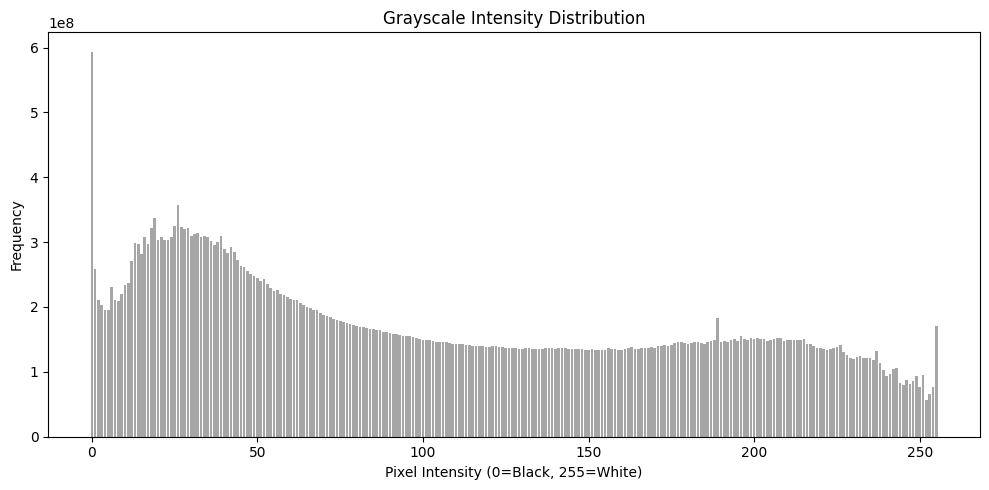

In [10]:
#One bin for each grayscale value
histogram = np.zeros(256, dtype=np.int64)

for file in real_files:
    img_path = os.path.join(DATASET_REAL_DIR, file)
    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)  # Load as grayscale

    if img is not None:
        hist, _ = np.histogram(img, bins=256, range=(0, 256))  # Compute histogram
        histogram += hist  # Accumulate the histogram

plt.figure(figsize=(10, 5))
plt.bar(range(256), histogram, color='gray', alpha=0.7)
plt.title("Grayscale Intensity Distribution")
plt.xlabel("Pixel Intensity (0=Black, 255=White)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.savefig(figure_folder / 'grayscale_intensity_distribution.png')
plt.show()

## Fake images

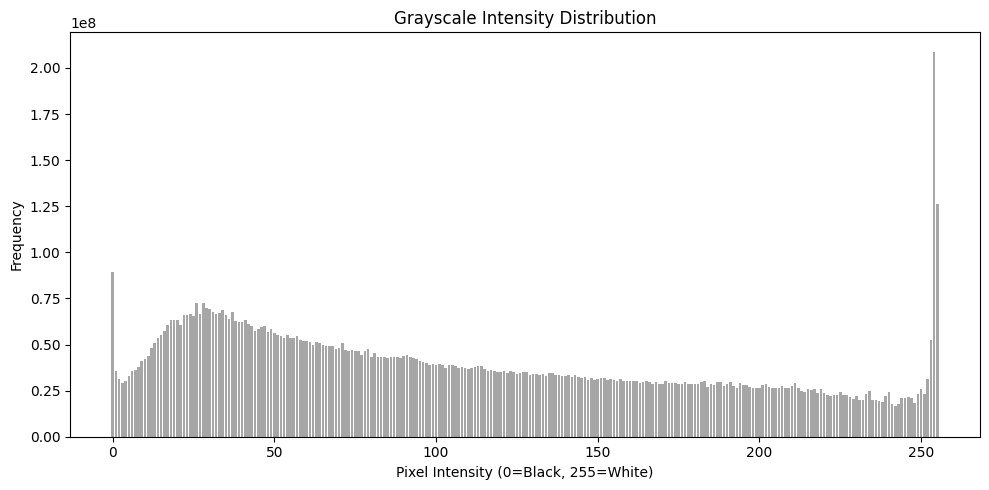

In [11]:
histogram = np.zeros(256, dtype=np.int64)

for file in fake_files:
    img_path = os.path.join(DATASET_FAKE_DIR, file)
    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)  # Load as grayscale

    if img is not None:
        hist, _ = np.histogram(img, bins=256, range=(0, 256))  # Compute histogram
        histogram += hist  

plt.figure(figsize=(10, 5))
plt.bar(range(256), histogram, color='gray', alpha=0.7)
plt.title("Grayscale Intensity Distribution")
plt.xlabel("Pixel Intensity (0=Black, 255=White)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.savefig(figure_folder / 'grayscale_intensity_distribution_fake.png')
plt.show()

## OUTLIERS REMOVING

In [12]:
def quartiles_method(Data):
    for column in Data.columns:
        if column == 'name':
            continue
        tempo = Data[column]
        q1 = tempo.quantile(0.25)
        q3 = tempo.quantile(0.75)
        lower = q1 - 1.5 * (q3 - q1)
        upper = q3 + 1.5 * (q3 - q1)
        Data = Data[Data[column] >= lower] 
        Data = Data[Data[column] <= upper]
    return Data

def z_score_method(Data):
    for column in Data.columns:
        if column == 'name':
            continue
        Data = Data[np.abs(Data[column] - Data[column].mean()) <= (3 * Data[column].std())]
    return Data

real_images_df_outliers = quartiles_method(real_images_df)
real_images_df_zscore= z_score_method(real_images_df_outliers)

print(f"Before removing outliers: {real_images_df.shape}")
print(f"After removing outliers: {real_images_df_outliers.shape}")
print(f"After removing outliers using z-score: {real_images_df_zscore.shape}")

print(real_images_df_zscore.head())


Before removing outliers: (6000, 4)
After removing outliers: (5866, 4)
After removing outliers using z-score: (5839, 4)
       name  width  height  aspect_ratio
0  0001.jpg   4000    2250      1.777778
1  0002.jpg   2592    1944      1.333333
2  0003.jpg   4899    3266      1.500000
3  0004.jpg   4480    6272      0.714286
5  0006.jpg   4288    2848      1.505618


In [13]:
fake_images_df_outliers = quartiles_method(fake_images_df)
fake_images_df_zscore= z_score_method(fake_images_df)

print(f"Before removing outliers: {fake_images_df.shape}")
print(f"After removing outliers: {fake_images_df_outliers.shape}")
print(f"After removing outliers using z-score: {fake_images_df_zscore.shape}")

print(fake_images_df_zscore.head())

Before removing outliers: (6000, 4)
After removing outliers: (2894, 4)
After removing outliers using z-score: (5716, 4)
       name  width  height  aspect_ratio
0  0001.jpg    853     853         1.000
1  0002.jpg    512     512         1.000
2  0003.jpg   2948    1760         1.675
3  0004.jpg    512     512         1.000
4  0005.jpg   1024    1024         1.000


We can see by using a outliers method there are a lot of in the fake images

In [14]:
def safe_loader(path):
    try:
        img = Image.open(path)
        if img.mode == 'P':
            img = img.convert("RGBA")
        img = img.convert("RGB")  
        return img
    except Exception as e:
        print(f"Skipping corrupted image: {path}")
        return None  # Skip corrupt images
    
for file in real_images_df_zscore['name']:
    img = safe_loader(f"{DATASET_REAL_DIR}/{file}")
    if img is None:
        real_images_df_zscore = real_images_df_zscore[real_images_df_zscore['name'] != file]

for file in fake_images_df_zscore['name']:
    img = safe_loader(f"{DATASET_FAKE_DIR}/{file}")
    if img is None:
        fake_images_df_zscore = fake_images_df_zscore[fake_images_df_zscore['name'] != file]

print(f"Real images after removing corrupted images: {real_images_df_zscore.shape}")
print(f"Fake images after removing corrupted images: {fake_images_df_zscore.shape}")

Skipping corrupted image: ..\dataset\complete_set\real/5197.jpg
Skipping corrupted image: ..\dataset\complete_set\real/5325.jpg
Skipping corrupted image: ..\dataset\complete_set\real/5879.jpg
Real images after removing corrupted images: (5836, 4)
Fake images after removing corrupted images: (5716, 4)


## Save into a file

In [15]:
real_images_df_zscore['name'].to_csv('real_images.csv', index=False)
fake_images_df_zscore['name'].to_csv('fake_images.csv', index=False)